# Notebook 5: Configuration analysis (`history/last_month/config.json`)

In this notebook I turn last month's configuration into readable tables and derived numbers (cost per query, price per slot, SLA feasibility and spot risk). These help explain the historical data and guide the scheduler.

The config matters because it defines the rules of the game: what machines cost, how fast each query type runs on each machine, what clients pay, and what a missed SLA costs. Every other notebook reads its data through these numbers. The scheduler reads the same structure while it runs, through `ctx.config`. Since the config can change in the middle of the month in the hidden scenarios, the scheduler has to *calculate* its decisions from it instead of hard-coding values from this file.

I checked the structure against `simkit/config.py`, which validates these keys:

- top level: `scenario`, `duration_s`, `tick_interval_s`, `max_queue_s`, `billing.minimum_s`, `engine_seed`
- `instance_types[type]`: `slots`, `on_demand_usd_per_hr`, `spot_usd_per_hr`, `spot_interruptions_per_hr`, `spot_notice_s`, `join_s`, `ready_s`, `on_demand_quota`, `spot_capacity`
- `runtime_matrix_s[query_type][instance_type]`: the benchmark (median) runtime in seconds on one slot
- `clients[client]`: `monthly_revenue_usd`, `sla_s[query_type]`, `penalty_per_miss_usd[query_type]`, `monthly_penalty_cap_usd`, `drop_penalty_usd`

`engine_seed` only seeds the simulator's random number generator (for spot interruptions). It is not a business parameter.

The notebook is organised as follows:

1. Loading and top-level settings
2. Machine specifications
3. Runtime benchmark matrix
4. Benchmark cost per query
5. Price vs slots vs speed: why the fastest machine is not always the cheapest
6. Client contracts and SLA terms
7. SLA feasibility per machine type
8. Spot market: interruption risk
9. Summary

## 1. Loading and top-level settings

Here I read the JSON file and print the settings that apply to the whole simulation.

These settings define the length of the month, how often the scheduler is called, when queries are dropped, and the billing minimum. I load the JSON with the standard-library `json` module, which turns it into nested Python dictionaries.

In [1]:
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def find_history_dir() -> Path:
    """Return the history/last_month folder, searching upwards from the working directory."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "history" / "last_month"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("Could not find history/last_month. Run from the project folder or analysis/.")


HISTORY_DIR = find_history_dir()
with open(HISTORY_DIR / "config.json") as f:
    config = json.load(f)

TYPE_ORDER = list(config["instance_types"])
QTYPE_ORDER = list(config["runtime_matrix_s"])
TYPE_COLORS = {"std.small": "#2a78d6", "std.large": "#eb6834", "mem.xlarge": "#1baf7a"}
plt.rcParams.update({
    "figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold",
})

print("Top-level keys:", list(config))
settings = pd.Series({
    "scenario": config["scenario"],
    "duration_s": config["duration_s"],
    "duration_days": config["duration_s"] / 86400,
    "tick_interval_s": config["tick_interval_s"],
    "max_queue_s (drop after)": config["max_queue_s"],
    "max_queue_hours": config["max_queue_s"] / 3600,
    "billing minimum_s": config["billing"]["minimum_s"],
    "engine_seed": config.get("engine_seed"),
})
settings.to_frame("value")

Top-level keys: ['scenario', 'duration_s', 'tick_interval_s', 'max_queue_s', 'billing', 'engine_seed', 'instance_types', 'runtime_matrix_s', 'clients']


,value
scenario,history_last_month
duration_s,2592000
duration_days,30.0000
tick_interval_s,60
max_queue_s (drop after),86400
max_queue_hours,24.0000
billing minimum_s,60
engine_seed,542


- **Simulation duration:** 2,592,000 s, which is **30 days**. Revenue and penalty caps are monthly and are prorated over this period.
- **Tick interval:** 60 s. The scheduler's `on_tick` runs every minute. (The fleet time series is sampled every 300 s, as shown in Notebook 3, but that is a logging choice, not the tick.)
- **Maximum queue age:** 86,400 s, which is **24 hours**. A query that has not *started* within 24 hours of arriving is dropped and costs the client's drop penalty.
- **Billing minimum:** 60 s. A machine terminated within a minute of launch is still billed for 60 seconds.

## 2. Machine specifications

Here I turn `instance_types` into a table and add some derived columns.

The derived columns are:

- `startup_s = join_s + ready_s`: the billed seconds before the machine can run anything.
- `od_per_slot_hr = on_demand_usd_per_hr / slots`: the price of one slot for one hour (on-demand).
- `spot_per_slot_hr = spot_usd_per_hr / slots`.
- `spot_discount_pct = (1 - spot / on-demand) * 100`.
- `startup_cost_od = startup_s / 3600 * on_demand_usd_per_hr`: what each launch costs before it does any work.
- `month_cost_od = 30 days * 24 h * on_demand_usd_per_hr`: the cost of keeping one machine for the whole month.

The config key called `ready_s` is the **warm-up duration**, not a timestamp. I rename it to `warmup_s` so it is not confused with the `ready_s` timestamp column in the instance log.

In [2]:
machines = pd.DataFrame(config["instance_types"]).T.loc[TYPE_ORDER].astype(float)
machines = machines.rename(columns={"ready_s": "warmup_s"})
machines["startup_s"] = machines["join_s"] + machines["warmup_s"]
machines["od_per_slot_hr"] = machines["on_demand_usd_per_hr"] / machines["slots"]
machines["spot_per_slot_hr"] = machines["spot_usd_per_hr"] / machines["slots"]
machines["spot_discount_pct"] = (1 - machines["spot_usd_per_hr"] / machines["on_demand_usd_per_hr"]) * 100
machines["startup_cost_od"] = machines["startup_s"] / 3600 * machines["on_demand_usd_per_hr"]
machines["month_cost_od"] = config["duration_s"] / 3600 * machines["on_demand_usd_per_hr"]
machines["max_od_slots"] = machines["on_demand_quota"] * machines["slots"]
machines["max_spot_slots"] = machines["spot_capacity"] * machines["slots"]
machines.T

,std.small,std.large,mem.xlarge
slots,2.0000,8.0000,16.0000
on_demand_usd_per_hr,0.1000,0.6800,2.7200
spot_usd_per_hr,0.0350,0.2200,0.9500
spot_interruptions_per_hr,0.0200,0.0400,0.0800
spot_notice_s,120.0000,120.0000,120.0000
join_s,45.0000,60.0000,90.0000
warmup_s,90.0000,180.0000,480.0000
on_demand_quota,200.0000,120.0000,60.0000
spot_capacity,100.0000,60.0000,25.0000
startup_s,135.0000,240.0000,570.0000


| | `std.small` | `std.large` | `mem.xlarge` |
|---|---|---|---|
| slots | 2 | 8 | 16 |
| on-demand \$/hr | 0.10 | 0.68 | 2.72 |
| **\$/slot-hour on-demand** | **0.050** | **0.085** | **0.170** |
| spot \$/hr | 0.035 | 0.22 | 0.95 |
| spot discount | 65% | about 68% | about 65% |
| start-up | 135 s | 240 s | 570 s |
| one launch's start-up cost (on-demand) | about \$0.004 | about \$0.045 | about \$0.43 |
| one machine for 30 days (on-demand) | \$72 | \$490 | \$1,958 |
| quota (on-demand / spot machines) | 200 / 100 | 120 / 60 | 60 / 25 |

A few things stand out from this table:

- **Per slot, bigger machines are more expensive.** A `mem.xlarge` slot costs 3.4 times as much as a `std.small` slot, so you are paying for speed, not for the number of slots.
- **Spot is about a third of the on-demand price** for every type.
- The quotas are far above last month's fleet (2, 6 and 6 machines), so the quota was never the limit. The fixed fleet size was a choice.
- **Start-up takes 2 to 10 minutes** and is billed. This matters for how quickly the fleet can respond to a burst.

(The 30-day cost shown here is \$1,958 per `mem.xlarge`. The instance log shows \$1,965.20 because the simulation ran 2.5 hours past 30 days.)

## 3. Runtime benchmark matrix

Here I show `runtime_matrix_s` as a table (rows are query types and columns are machine types), along with how much faster each machine is than `std.small`.

According to the README and `engine.py`, each value is the **median runtime in seconds on one slot**. A query's actual runtime is this value multiplied by a hidden per-query factor. Notebook 4 found typical factors from about 0.2 to 5, and they are very stable within a template.

I use `speedup_vs_small = runtime(std.small) / runtime(machine)`.

In [3]:
runtime = pd.DataFrame(config["runtime_matrix_s"]).T.loc[QTYPE_ORDER, TYPE_ORDER]
speedup = runtime.rdiv(runtime["std.small"], axis=0)
print("Benchmark runtime (seconds, one slot):")
display(runtime)
print("Speed-up relative to std.small (higher = faster):")
speedup.round(2)

Benchmark runtime (seconds, one slot):


,std.small,std.large,mem.xlarge
lookup,0.3000,0.2500,0.2000
dashboard,7.0000,3.0000,2.4000
filtered_agg,650.0000,240.0000,130.0000
adhoc,"3,000.0000","1,125.0000",450.0000
report,"45,000.0000","16,200.0000","5,400.0000"


Speed-up relative to std.small (higher = faster):


,std.small,std.large,mem.xlarge
lookup,1.0000,1.2000,1.5000
dashboard,1.0000,2.3300,2.9200
filtered_agg,1.0000,2.7100,5.0000
adhoc,1.0000,2.6700,6.6700
report,1.0000,2.7800,8.3300


Short queries barely benefit from a bigger machine: `lookup` goes from 0.30 s to 0.20 s on `mem.xlarge` (1.5 times faster).

Long queries benefit a lot: `adhoc` goes from 3,000 s to 450 s (**6.7 times faster**), `report` from 45,000 s to 5,400 s (**8.3 times**), and `filtered_agg` from 650 s to 130 s (5 times).

Going from `std.large` to `mem.xlarge` gives only a small speed-up for `dashboard` (3 s to 2.4 s), but a large one for `adhoc` (1,125 s to 450 s, 2.5 times) and `report` (3 times).

Whether that speed is worth paying for depends on the price per slot, which I combine with it next.

## 4. Benchmark cost per query

Here I calculate what one query of each type costs on each machine type, at the benchmark runtime, both on-demand and on spot.

I use the same cost-allocation assumption as `cost_per_query_usd` in `simkit/config.py` and the README table:

`cost_per_query = runtime_s * price_per_hour / slots / 3600`

This only charges a query for **the slot-time it takes up**, assuming the machine's other slots are paid for by other queries. It ignores idle time, start-up time and the billing minimum. So it is a **lower bound on the real cost** when machines are not fully used. Last month's fleet was about 26% utilised, so the real cost per query was roughly four times higher. It also uses the benchmark runtime, not the actual runtime of a specific query.

To confirm that I am using the same formula, I check my numbers against one cell of the README's "cost per 1,000 queries" table.

In [4]:
def cost_per_query(qt: str, it: str, market: str) -> float:
    spec = config["instance_types"][it]
    price = spec["on_demand_usd_per_hr"] if market == "on_demand" else spec["spot_usd_per_hr"]
    return config["runtime_matrix_s"][qt][it] * price / spec["slots"] / 3600


cost_od = pd.DataFrame({it: [cost_per_query(qt, it, "on_demand") for qt in QTYPE_ORDER] for it in TYPE_ORDER}, index=QTYPE_ORDER)
cost_spot = pd.DataFrame({it: [cost_per_query(qt, it, "spot") for qt in QTYPE_ORDER] for it in TYPE_ORDER}, index=QTYPE_ORDER)

# README states adhoc on mem.xlarge = $21.25 per 1,000 on-demand, $7.42 spot
assert abs(cost_od.loc["adhoc", "mem.xlarge"] * 1000 - 21.25) < 0.01
assert abs(cost_spot.loc["adhoc", "mem.xlarge"] * 1000 - 7.42) < 0.01

summary = pd.DataFrame({
    "cheapest on-demand": cost_od.idxmin(axis=1),
    "fastest": runtime.idxmin(axis=1),
    "cost on fastest / cost on cheapest": [cost_od.loc[q, runtime.loc[q].idxmin()] / cost_od.loc[q].min() for q in QTYPE_ORDER],
})
print("Cost per 1,000 queries, ON-DEMAND (USD):")
display((cost_od * 1000).round(4))
print("Cost per 1,000 queries, SPOT (USD):")
display((cost_spot * 1000).round(4))
summary.round(2)

Cost per 1,000 queries, ON-DEMAND (USD):


,std.small,std.large,mem.xlarge
lookup,0.0042,0.0059,0.0094
dashboard,0.0972,0.0708,0.1133
filtered_agg,9.0278,5.6667,6.1389
adhoc,41.6667,26.5625,21.2500
report,625.0000,382.5000,255.0000


Cost per 1,000 queries, SPOT (USD):


,std.small,std.large,mem.xlarge
lookup,0.0015,0.0019,0.0033
dashboard,0.0340,0.0229,0.0396
filtered_agg,3.1597,1.8333,2.1441
adhoc,14.5833,8.5938,7.4219
report,218.7500,123.7500,89.0625


,cheapest on-demand,fastest,cost on fastest / cost on cheapest
lookup,std.small,mem.xlarge,2.2700
dashboard,std.large,mem.xlarge,1.6000
filtered_agg,std.large,mem.xlarge,1.0800
adhoc,mem.xlarge,mem.xlarge,1.0000
report,mem.xlarge,mem.xlarge,1.0000


The values match the README table (the assertions passed).

The **cheapest on-demand machine for each type** is `std.small` for `lookup`, `std.large` for `dashboard` and `filtered_agg`, and `mem.xlarge` for `adhoc` and `report`. This is exactly last month's routing (Notebook 4).

The **fastest machine** is `mem.xlarge` for every type.

For `adhoc` and `report`, the fastest machine is also the cheapest, because its speed-up (2.5 to 3 times over `std.large`) is bigger than its price-per-slot ratio (2 times).

For `lookup`, the fastest machine costs about 2.3 times as much as the cheapest. For `dashboard` it is about 1.6 times, and for `filtered_agg` about 1.08 times (nearly the same).

Spot changes the absolute costs (to about a third), but not the ranking, because all three types have similar spot discounts.

To give a sense of scale, a `report` costs about \$0.26 on-demand at benchmark on `mem.xlarge`, while a `lookup` costs about \$0.000004. One report costs as much as roughly 60,000 lookups.

## 5. Price vs slots vs speed: why the fastest machine is not always the cheapest

Here I look at the trade-off behind the table above, as a single ratio per query type and machine.

The reasoning is this. Moving a query from machine A to a faster machine B multiplies its slot-time by `runtime_B / runtime_A` and its price per slot-second by `price_per_slot_B / price_per_slot_A`. The cost changes by these two multiplied together. So the fastest machine is only cheaper when its **speed-up is bigger than its extra price per slot**.

Relative to `std.large`, I use:

- `speedup = runtime(std.large) / runtime(machine)`
- `slot_price_ratio = price_per_slot(machine) / price_per_slot(std.large)`
- `relative_cost = slot_price_ratio / speedup` (below 1 means cheaper than `std.large`)

In [5]:
base = "std.large"
slot_price = machines["od_per_slot_hr"]
tradeoff = pd.DataFrame({
    (it, col): (runtime[base] / runtime[it] if col == "speedup" else
                pd.Series(slot_price[it] / slot_price[base], index=QTYPE_ORDER) if col == "slot_price_ratio" else
                (slot_price[it] / slot_price[base]) / (runtime[base] / runtime[it]))
    for it in TYPE_ORDER for col in ["speedup", "slot_price_ratio", "relative_cost"]})
tradeoff.round(3)

std.small                                std.large                                mem.xlarge                               
               speedup slot_price_ratio relative_cost   speedup slot_price_ratio relative_cost    speedup slot_price_ratio relative_cost
lookup          0.8330           0.5880        0.7060    1.0000           1.0000        1.0000     1.2500           2.0000        1.6000
dashboard       0.4290           0.5880        1.3730    1.0000           1.0000        1.0000     1.2500           2.0000        1.6000
filtered_agg    0.3690           0.5880        1.5930    1.0000           1.0000        1.0000     1.8460           2.0000        1.0830
adhoc           0.3750           0.5880        1.5690    1.0000           1.0000        1.0000     2.5000           2.0000        0.8000
report          0.3600           0.5880        1.6340    1.0000           1.0000        1.0000     3.0000           2.0000        0.6670

**A `mem.xlarge` slot costs 2 times as much as a `std.large` slot.** So `mem.xlarge` is only cheaper if it is more than 2 times faster. That is true for `adhoc` (2.5 times) and `report` (3 times), but not for `dashboard` (1.25 times) or `lookup` (1.25 times). `filtered_agg` almost breaks even (1.85 times faster, which gives a relative cost of about 1.08).

**A `std.small` slot costs 0.59 times as much as a `std.large` slot.** So `std.small` is only cheaper if it is less than 1.7 times slower. That is true for `lookup` (1.2 times slower), but not for `dashboard` (2.3 times slower) or the long types.

The reason the fastest machine is not automatically the cheapest is that price grows faster than the number of slots. Per slot, the big machine is a premium product, and its speed only pays for itself on work that scales well with machine size (long analytical queries).

**However, cost per query is not the whole story.** A slower, cheaper choice can miss an SLA (and pay a penalty), or keep a slot busy for longer, which makes queues longer. The scheduler has to weigh cost per query against deadline risk, which is what Section 7 looks at.

### 5.1 Chart: relative cost by query type and machine

I used grouped bars around a reference line at 1.0, so it is easy to see where each machine is cheaper or more expensive than `std.large` for each query type. I used a log scale because ratios above and below 1 should look symmetric (0.5 times and 2 times are equally far from 1).

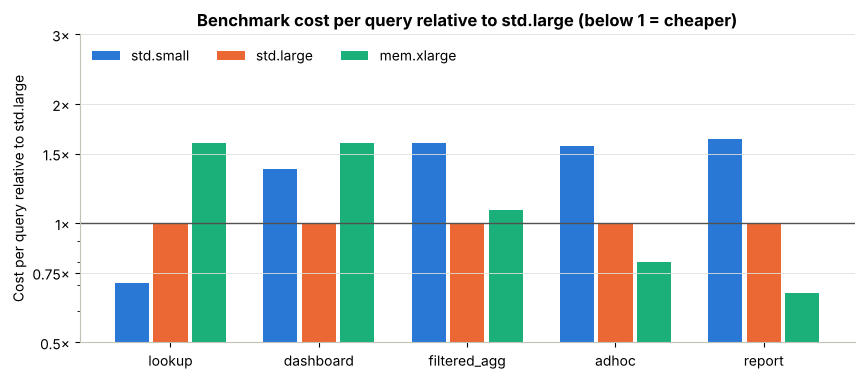

In [6]:
rel = pd.DataFrame({it: tradeoff[(it, "relative_cost")] for it in TYPE_ORDER})
x = np.arange(len(QTYPE_ORDER))
width = 0.26
fig, ax = plt.subplots(figsize=(10, 4))
for i, it in enumerate(TYPE_ORDER):
    ax.bar(x + (i - 1) * width, rel[it], width=width - 0.03, color=TYPE_COLORS[it], label=it)
ax.axhline(1, color="#52514e", linewidth=1)
ax.set_yscale("log")
ax.set_yticks([0.5, 0.75, 1, 1.5, 2, 3])
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.set_xticks(x)
ax.set_xticklabels(QTYPE_ORDER)
ax.set_ylabel("Cost per query relative to std.large")
ax.set_title("Benchmark cost per query relative to std.large (below 1 = cheaper)")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()

Bars below the 1.0 line are cheaper than `std.large` for that query type. `std.small` (blue) is only below the line for `lookup`, and `mem.xlarge` (aqua) is only below the line for `adhoc` and `report`.

## 6. Client contracts and SLA terms

Here I build two tables. The first has the terms for each client: revenue, penalty cap, drop penalty, and the cap as a share of revenue. The second has the SLA terms for each client and query type.

These decide how much each client is worth and how much a bad month can cost.

I use these formulas:

- `daily_revenue = monthly_revenue / 30` (the engine prorates revenue by time, and it is earned no matter how good the service is).
- `cap_share_of_revenue = monthly_penalty_cap / monthly_revenue`.
- `misses_to_reach_cap = cap / penalty_per_miss` (per query type, as if all misses were of that type).

In [7]:
clients = pd.DataFrame({
    c: {"monthly_revenue_usd": v["monthly_revenue_usd"],
        "daily_revenue_usd": v["monthly_revenue_usd"] / 30,
        "monthly_penalty_cap_usd": v["monthly_penalty_cap_usd"],
        "cap_share_of_revenue_pct": (v["monthly_penalty_cap_usd"] / v["monthly_revenue_usd"] * 100
                                     if v["monthly_revenue_usd"] else np.nan),
        "drop_penalty_usd": v["drop_penalty_usd"],
        "query_types": ", ".join(v["sla_s"])}
    for c, v in config["clients"].items()}).T
print(f"Total monthly revenue: ${clients['monthly_revenue_usd'].sum():,.0f}")
display(clients)

sla_rows = []
for c, v in config["clients"].items():
    for qt, sla in v["sla_s"].items():
        pen = v["penalty_per_miss_usd"][qt]
        sla_rows.append({"client_id": c, "query_type": qt, "sla_s": sla, "sla_readable":
                         f"{sla:g} s" if sla < 60 else f"{sla / 60:g} min" if sla < 3600 else f"{sla / 3600:g} h",
                         "penalty_per_miss_usd": pen,
                         "misses_to_reach_cap": (v["monthly_penalty_cap_usd"] / pen) if pen > 0 else np.nan})
sla_terms = pd.DataFrame(sla_rows).set_index(["client_id", "query_type"])
sla_terms

Total monthly revenue: $18,000


,monthly_revenue_usd,daily_revenue_usd,monthly_penalty_cap_usd,cap_share_of_revenue_pct,drop_penalty_usd,query_types
acme_retail,9000,300.0000,3600,40.0000,2.0000,"dashboard, filtered_agg, report"
finpay,6000,200.0000,2400,40.0000,2.0000,"lookup, filtered_agg"
labs_ds,3000,100.0000,900,30.0000,1.0000,"adhoc, report"
trial_pool,0,0.0000,0,NaN,0.2500,"adhoc, dashboard"


sla_s sla_readable  penalty_per_miss_usd  misses_to_reach_cap
client_id   query_type                                                                      
acme_retail dashboard        10.0000         10 s                0.1000          36,000.0000
            filtered_agg    900.0000       15 min                0.5000           7,200.0000
            report       21,600.0000          6 h                5.0000             720.0000
finpay      lookup            1.5000        1.5 s                0.1000          24,000.0000
            filtered_agg    600.0000       10 min                0.5000           4,800.0000
labs_ds     adhoc         1,800.0000       30 min                0.2000           4,500.0000
            report       43,200.0000         12 h                1.0000             900.0000
trial_pool  adhoc         7,200.0000          2 h                0.0000                  NaN
            dashboard        60.0000        1 min                0.0000                  NaN

**Revenue:** acme\_retail pays \$9,000, finpay \$6,000, labs\_ds \$3,000 and trial\_pool \$0, for a **total of \$18,000 per month** (\$600 per day).

**Penalty caps** are **40% of revenue** for acme\_retail (\$3,600 of \$9,000) and finpay (\$2,400 of \$6,000), and **30%** for labs\_ds (\$900 of \$3,000). trial\_pool's cap is \$0. The cap limits the worst-case miss-penalty loss for each client.

**Drop penalties** are \$2 (acme\_retail and finpay), \$1 (labs\_ds) and \$0.25 (trial\_pool). Drops are not capped, so dropping a lot of queries would be expensive.

**The SLA terms differ by client for the same query type.** `adhoc` is 30 minutes and \$0.20 for labs\_ds, but 2 hours and \$0 for trial\_pool. `filtered_agg` is 15 minutes for acme\_retail but 10 minutes for finpay. `dashboard` is 10 seconds for acme\_retail but 60 seconds for trial\_pool.

**Misses to reach the cap:** labs\_ds reaches its \$900 cap after 4,500 `adhoc` misses (or 900 report misses). acme\_retail needs 36,000 dashboard misses to reach its cap, but only 720 report misses, because each one costs \$5.

For the scheduler, this means not every miss costs the same. The scheduler should rank waiting queries by the money at stake (the penalty and the remaining spare time), not by the order they arrived. Once a client's cap is reached, its extra misses cost nothing, and the scheduler can see this through `ctx.client_stats()`.

## 7. SLA feasibility per machine type

For each client and query type, I check whether the benchmark runtime fits inside the SLA on each machine type, and how much spare time is left.

A machine whose benchmark runtime is already longer than the SLA can never meet it, even with no waiting. A machine whose runtime is close to the SLA will miss whenever the query's hidden multiplier is above 1, or whenever the query has to wait.

I use `runtime_share_of_sla = benchmark_runtime / sla_s`. Values above 1 mean the SLA is impossible at the benchmark. I also show the spare time in seconds (`sla - runtime`) and how many times the benchmark runtime fits inside the SLA (`sla / runtime`). This last number can be compared with the multiplier tails in Notebook 4 (the P99 multiplier is about 2.7 for `filtered_agg` and about 5.2 for `adhoc`).

In [8]:
feas_rows = []
for c, v in config["clients"].items():
    for qt, sla in v["sla_s"].items():
        row = {"client_id": c, "query_type": qt, "sla_s": sla}
        for it in TYPE_ORDER:
            rt = config["runtime_matrix_s"][qt][it]
            row[(it, "max multiplier that fits")] = sla / rt
        feas_rows.append(row)
feasibility = pd.DataFrame(feas_rows).set_index(["client_id", "query_type", "sla_s"])
feasibility.columns = pd.MultiIndex.from_tuples(feasibility.columns)
feasibility.round(2)

std.small                std.large               mem.xlarge
                                     max multiplier that fits max multiplier that fits max multiplier that fits
client_id   query_type   sla_s                                                                                 
acme_retail dashboard    10.0000                       1.4300                   3.3300                   4.1700
            filtered_agg 900.0000                      1.3800                   3.7500                   6.9200
            report       21,600.0000                   0.4800                   1.3300                   4.0000
finpay      lookup       1.5000                        5.0000                   6.0000                   7.5000
            filtered_agg 600.0000                      0.9200                   2.5000                   4.6200
labs_ds     adhoc        1,800.0000                    0.6000                   1.6000                   4.0000
            report       43,200.0000                   0.9600                   2.6700                   8.0000
trial_pool  adhoc        7,200.0000                    2.4000                   6.4000                  16.0000
            dashboard    60.0000                       8.5700                  20.0000                  25.0000

Each cell shows how large a query's multiplier can be while still finishing in time **if it starts straight away** on that machine. Below 1 means the benchmark itself is too slow.

- `report` on `std.small` (45,000 s) does **not** fit acme's 6-hour SLA (0.48) and only just fits labs' 12-hour SLA (0.96). On `std.large` (16,200 s = 4.5 h), it fits with a modest margin (1.33 for acme and 2.67 for labs).
- `adhoc` for labs\_ds (30 minutes): `std.small` fails (0.6), `std.large` allows multipliers up to 1.6, and `mem.xlarge` up to 4. Since the typical multiplier tail goes up to about 5, only `mem.xlarge` protects the heavy queries.
- `filtered_agg` for finpay (10 minutes): `std.small` fails (0.92), `std.large` allows 2.5, and `mem.xlarge` 4.6. Notebook 4 found that all the "run alone" `filtered_agg` misses ran on `std.large`, which means their multipliers were above 2.5 to 3.75.
- `dashboard` for acme (10 seconds): `std.small` allows 1.4 (risky), `std.large` 3.3, and `mem.xlarge` 4.2. There is little room for waiting.
- `lookup` for finpay (1.5 seconds) fits on every machine with a margin of at least 5, but there is almost no room for queueing.

For the scheduler, a runtime estimate for each query (from template history, Notebook 4) means it can choose the cheapest machine on which *this* query still meets its deadline (including the expected waiting), instead of using a fixed type for each query type.

## 8. Spot market: interruption risk

Here I look at what the spot settings mean for work running on spot machines.

The model comes from `engine.py`. Each spot machine gets an interruption time drawn from an exponential distribution, with a rate of `rate = spot_interruptions_per_hr / 3600` per second. This means interruptions are random and memoryless, and the average time between them is `1 / rate`. The machine gets a notice `spot_notice_s` (120 s) before it is taken away. Any queries running at that moment are returned to the scheduler and **start again from scratch**.

I use these formulas:

- average time to interruption (hours) = `1 / spot_interruptions_per_hr`
- the chance that a query with a runtime of `r` seconds is interrupted while running = `1 - exp(-rate * r)` (assuming it runs on one spot machine for `r` seconds)
- the expected effective cost on spot compared with on-demand is roughly `spot price * (1 + expected wasted fraction)`. I only show the interruption probabilities, because the wasted fraction depends on how the scheduler behaves (for example, draining on notice).

This analysis only uses config values. Last month had **no spot usage**, so there is no historical evidence to check it against.

In [9]:
spot = pd.DataFrame({
    "interruptions_per_hr": machines["spot_interruptions_per_hr"],
    "mean_hours_between_interruptions": 1 / machines["spot_interruptions_per_hr"],
    "notice_s": machines["spot_notice_s"],
    "spot_usd_per_hr": machines["spot_usd_per_hr"],
    "spot_capacity_machines": machines["spot_capacity"],
})
interrupt_prob = pd.DataFrame({
    it: [1 - math.exp(-machines.loc[it, "spot_interruptions_per_hr"] / 3600 * config["runtime_matrix_s"][qt][it])
         for qt in QTYPE_ORDER] for it in TYPE_ORDER}, index=QTYPE_ORDER) * 100
print("Spot market parameters:")
display(spot)
print("Probability (%) that a query running at benchmark time on a spot machine is interrupted:")
interrupt_prob.round(3)

Spot market parameters:


,interruptions_per_hr,mean_hours_between_interruptions,notice_s,spot_usd_per_hr,spot_capacity_machines
std.small,0.0200,50.0000,120.0000,0.0350,100.0000
std.large,0.0400,25.0000,120.0000,0.2200,60.0000
mem.xlarge,0.0800,12.5000,120.0000,0.9500,25.0000


Probability (%) that a query running at benchmark time on a spot machine is interrupted:


,std.small,std.large,mem.xlarge
lookup,0.0000,0.0000,0.0000
dashboard,0.0040,0.0030,0.0050
filtered_agg,0.3600,0.2660,0.2880
adhoc,1.6530,1.2420,0.9950
report,22.1200,16.4730,11.3080


The average time between interruptions per machine is **50 hours** for `std.small`, **25 hours** for `std.large` and **12.5 hours** for `mem.xlarge`. Bigger machines are interrupted more often.

For short queries the risk is tiny (a `dashboard` has about a 0.003% chance on `std.large`).

For long queries it matters. A `report` on spot `mem.xlarge` has about an **11%** chance of being interrupted on each attempt, about 16.5% on spot `std.large` (4.5 h), and about 22% on spot `std.small` (12.5 h). With multipliers above 1, the risk goes up further.

The 120-second notice is long enough to stop giving new work to a machine that is about to go and to launch a replacement, but not long enough to finish a long query that is already running.

For the scheduler, spot is about 65% cheaper, so even with the occasional restart it is usually worth it for work with spare time (reports with 6 to 12 hour SLAs, and `trial_pool`, which has no penalties) and for short queries. It is riskier for long queries with tight SLAs (`adhoc` for labs\_ds). Spot capacity limits (25 `mem.xlarge` spot machines) also limit how much work can move to spot. The hidden scenarios may change spot prices and rates in the middle of the month (as `dev_changes` does), so the decision should be recalculated from `ctx.config`.

## 9. Summary

**Settings:** a 30-day month, a 60-second tick, a 24-hour drop limit and a 60-second billing minimum.

**Machines:** the price per slot goes up with size (\$0.05, \$0.085 and \$0.17 per slot-hour on-demand). Spot is about 65% to 68% cheaper. Start-up takes 135, 240 and 570 seconds. The quotas are far above last month's 14-machine fleet.

**Runtime and cost:** the speed-up grows with query length (1.5 times for lookup and 8.3 times for report, from the smallest machine to the largest). The cheapest machine for each type is `std.small` for lookup, `std.large` for dashboard and filtered\_agg, and `mem.xlarge` for adhoc and report, which is last month's routing. The fastest machine (`mem.xlarge`) is only the cheapest where its speed-up is bigger than its price per slot, which is 2 times that of `std.large`.

**Contracts:** revenue is \$18,000 per month. The caps are 40% of revenue for acme\_retail and finpay, 30% for labs\_ds, and \$0 for trial\_pool. Penalties per miss range from \$0 to \$5, and drop penalties range from \$0.25 to \$2 and are not capped. The same query type has different SLAs and penalties for different clients.

**Feasibility:** some combinations of machine and type cannot meet the SLA even at the benchmark (report on `std.small` for acme, adhoc on `std.small` for labs, and filtered\_agg on `std.small` for finpay). Tight SLAs only leave room for small multipliers.

**Spot:** the interruption risk is tiny for short queries and around 11% to 22% per attempt for long reports at the benchmark.

**What this means for the scheduler**

1. Calculate routing from `ctx.config` (cost per query and SLA fit) and never from hard-coded types, because configs change in the middle of the month.
2. Use runtime estimates for each query, so the "cheapest machine that still meets the deadline" can be chosen query by query.
3. Use spot for work with spare time and for short work, with a plan for notices. Prefer on-demand for long queries with tight SLAs.
4. Take start-up delay and cost into account when scaling, especially for `mem.xlarge` (9.5 minutes, about \$0.43 on-demand per launch).